---
title: "Parametric sensitivity and runaway in a fixed bed"
description: "Two 1970 criteria for when a cooled tubular reactor stops being controllable, rebuilt, then swept over the whole operating plane the original could only sample."
categories: [sec:D, struct:S2, tier:T0, data:tier6, phase:gas-solid]
date: 2026-07-27
---

# Parametric sensitivity and runaway in a fixed bed

**Catalog ID:** `D2.2` · **Structures:** `S2` (plug flow with reaction) · **Tier:** T0

An exothermic reaction in a cooled tube always makes a hot spot. Raise the inlet
concentration a few percent and the hot spot may rise a few degrees, or it may
rise by hundreds. There is a boundary, and Van Welsenaere and Froment found two
ways to locate it without integrating anything.

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "gallery-2026.11.01"  # replaced by the release tag at publication
PYMRM = ">=3.3.0,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "D2.2-van-welsenaere-froment-runaway"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
from dataclasses import replace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from gallery_utils import load_data, load_meta, cite_data, Claims
from model import (VWFCase, kexp, maxima_curve, ps_curve, t_max_peak, t_tangency,
                   inlet_limits, back_integrate, critical_points, RunawayTube,
                   critical_p0, critical_p0_bisect)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
claims = Claims(PAGE.split("-")[0])

## Background

Put an exothermic reaction in a tube with a cooled wall and the temperature
profile has a maximum. Where that maximum sits is a design question with
consequences: too hot and the catalyst sinters, the selectivity collapses, or
the tube itself creeps. What makes it hard is that the hot spot is not merely
sensitive to the operating variables: over part of the range it is *violently*
sensitive. In the base case of this paper at $T_w$ = 625 K, 5 % more inlet
pressure from 0.0164 atm raises the hot spot by 7.47 K, while 1 % more from
0.0182 atm raises it by 304 K (both computed below, converged in the grid; on
the page's default 1500 cells they are 7.4 K and 304 K).

Before 1970 there were two ways to deal with this. Bilous and Amundson (1956)
perturbed a known steady state, which requires having integrated the reactor
first. Barkelew (1959) integrated a very large number of cases and condensed the
results into an empirical chart, which requires trial and error to use and is
tied to his modified rate expression.

Van Welsenaere and Froment did something different: they looked for **intrinsic**
features of the solution, characteristic points that exist in the temperature
profile whether or not anyone has computed it, and translated them into the
*p*–*T* phase plane, where they become geometry. The result is a set of
closed-form inequalities on the inlet conditions. No computer, which in 1970 was
the point.

Note the terminology, which they are careful about: with gas and solid at the
same temperature, an ideal tubular reactor is always stable in the strict sense.
There is no bifurcation here. "Runaway" is a statement about *sensitivity*, not
about multiplicity, which is what distinguishes this page from
[`B1.1`](../B1.1-thiele-weisz-hicks/), where the multiplicity is real.

## The published model

**Reactor** (their Eqs. 3–4). One dimension, pseudo-homogeneous, constant wall
temperature, single irreversible pseudo-first-order reaction:

$$
\frac{\mathrm{d}p}{\mathrm{d}z} = -A\,p\,\mathrm{e}^{-a/T+b},
\qquad
\frac{\mathrm{d}T}{\mathrm{d}z} = B\,p\,\mathrm{e}^{-a/T+b} - C\,(T-T_w),
$$

$$
A = \frac{M P \rho_b}{\rho_g} p_B^0, \qquad
B = \frac{(-\Delta H)\rho_b}{c_p} p_B^0, \qquad
C = \frac{2U}{c_p R}, \qquad z = \frac{z'}{u},
$$

with $p = p^0$ and $T = T_0 = T_w$ at $z = 0$. The axial coordinate is a contact
time, not a length.

**The *p*–*T* plane.** Dividing one equation by the other removes $z$
altogether, so every reactor is a single trajectory in the $(T, p)$ plane. Two
loci live in that plane and neither depends on the inlet conditions:

- the **maxima curve** (Eq. 7), where $\mathrm{d}T/\mathrm{d}z = 0$:
  $p_m = (T_m - T_w) \big/ \left[\tfrac{B}{C}\mathrm{e}^{-a/T_m+b}\right]$;
- the **$p_s$ curve** (Eq. 18), the locus of the inflexion points that appear
  *before* the maximum: $p_s = T_i^2 \big/ \left[a\tfrac{B}{C}\mathrm{e}^{-a/T_i+b}\right]$.

**First criterion.** The maxima curve has a maximum of its own, at

$$
T_M = \tfrac{1}{2}\left[a - \sqrt{a\,(a - 4T_w)}\right] \qquad (8)
$$

A trajectory that crosses the maxima curve *beyond* its peak is one where a
further small increase in $p^0$ moves the hot spot sharply. So: **the trajectory
through the maximum of the maxima curve is critical.**

**Second criterion.** An inflexion point *before* the maximum is what makes the
hot spot grow. So: **the critical trajectory is the one tangent to the $p_s$
curve.** The tangency condition reduces to one implicit equation in
$t = a/T_i$ (Eq. 20),

$$
K = \frac{t-2}{t\,\mathrm{e}^{-t+20}}\left[1 - t\left(1 - \frac{t}{t_w}\right)\right],
\qquad K = \frac{A}{C}\mathrm{e}^{b-20}, \quad t_w = \frac{a}{T_w},
$$

which the paper solves *graphically*, through its Figs. 6 and 7, to avoid
needing a computer.

**From the critical point to the inlet.** Both criteria give a critical
$(T_{cr}, p_{cr})$ inside the reactor; getting back to the inlet needs an
extrapolation, and the paper gives a lower and an upper limit rather than one
value:

$$
(p^0)_l = \frac{T_{cr}^2}{a\frac{B}{C}\mathrm{e}^{-a/T_{cr}+b}} + \frac{A}{B}(T_{cr}-T_0)
\quad (27), \qquad
(p^0)_u = \frac{A}{B}(T_{cr}-T_w)\left[\frac{1}{\sqrt{X}} + 1\right]^2 \quad (28),
$$

with $X = \frac{A}{C}\mathrm{e}^{-a/T_{cr}+b}$. Their empirical observation, the
one that makes the method usable, is that the **mean of the two limits is an
excellent estimate of the true critical inlet pressure**, and for the first
criterion that mean has the closed form (30)

$$
(p^0)_m = \frac{A}{B}(T_M-T_w)\left[1 + \frac{1}{\sqrt{X}} + \frac{1}{X}\right].
$$

## Parameters and assumptions

**Assumptions:** one dimension, no axial dispersion; pseudo-homogeneous, so gas
and solid share a temperature; constant wall temperature; constant fluid
density and velocity; a single irreversible reaction, pseudo-first-order in the
limiting reactant with the second reactant in excess at $p_B^0$; ideal gas.

**One trap in this paper, and it is a units trap.** $c_p$ is printed as
kcal/m³·°C: it is already a *volumetric* heat capacity. Multiplying it by
$\rho_g$ "to fix the units" changes $B$ and $C$ by that factor and moves the
runaway boundary with no other symptom; the break table below runs it. $\rho_g$
appears only in $A$.

**One trap in getting the numbers out.** This is a 1970 scan and the Elsevier
full-text API returns the publisher's OCR of it, which discards the mid-dot
decimal separator: `R = 00125 m` for 0.0125 m, `b = 19837` for 19.837,
`001353` for 0.01353 atm. The API is excellent for prose and useless for
numbers. Everything below was read from a 600 dpi render of the printed page,
and the validation section shows the check that the reading is right.

In [3]:
par = load_data("van-welsenaere-froment-1970-parameters.csv", page=PAGE)
print(par.to_string(index=False))

CASE = VWFCase.from_table(zip(par.symbol, par.value))
TW = 625.0                     # K, the wall (and inlet) temperature of Examples 1 and 2
print(f"\nA = {CASE.A:.6g} 1/hr,  B = {CASE.B:.6g} K/(hr atm),  C = {CASE.C:.6g} 1/hr")

  symbol       value              unit                                         description
       M     29.4800           kg/kmol                               mean molecular weight
       P      1.0000               atm                                      total pressure
   rho_b   1300.0000             kg/m3                               catalyst bulk density
   rho_g      1.2930             kg/m3                                         gas density
minus_dH 307000.0000         kcal/kmol                                    heat of reaction
     c_p      0.3230    kcal/(m3 degC)                 volumetric heat capacity of the gas
       u   3600.0000              m/hr                                superficial velocity
       U     82.7000 kcal/(m2 hr degC)              overall wall heat transfer coefficient
       R      0.0125                 m        tube radius (base case; varied in Example 4)
    p_B0      0.2080               atm partial pressure of the second reactant (in excess)

## The data

Two datasets. The **parameters** are the base case of their Section 1. The
**examples** are every number printed in their Section 6: four worked problems,
including the intermediate steps, so a reimplementation can be checked stage by
stage rather than only at the answer.

**These are not measurements.** The paper contains no experimental data at all;
its numbers are partly closed-form extrapolations and partly its own
fourth-order Runge–Kutta integrations. This page is therefore provenance tier 6,
validated against a published reference solution in the same sense as
[`B1.1`](../B1.1-thiele-weisz-hicks/) and [`F3.1`](../F3.1-hatta-regimes/). The
`kind` column separates the two, because a criterion value and an integration
value test different things and should not be pooled.

In [4]:
ex = load_data("van-welsenaere-froment-1970-examples.csv", page=PAGE)
ex_meta = load_meta("van-welsenaere-froment-1970-examples.csv", page=PAGE)


def paper(example, quantity):
    """A value printed in Section 6, read from the examples CSV."""
    hit = ex[(ex.example == example) & (ex.quantity == quantity)]
    return float(hit.value.iloc[0])


print(ex.groupby(["example", "kind"]).size().unstack(fill_value=0).to_string())
print(f"\n{cite_data(ex_meta)}")
print(f"provenance tier {ex_meta['provenance_tier']['tier']}: "
      + " ".join(ex_meta["provenance_tier"]["note"].split())[:96] + " ...")

kind     criterion  integration
example                        
1a               4            1
1b              10            1
2                1            2
3                4            1
4                6            0

Van Welsenaere, R. J.; Froment, G. F. (1970) — Chemical Engineering Science 25(10) 1503-1516 — doi:10.1016/0009-2509(70)85073-4 — table
provenance tier 6: THESE ARE NOT MEASUREMENTS. They are the authors' own computed values - partly closed-form extra ...


## PyMRM implementation

Two pieces, both in `model.py` next to this notebook. The **reactor**,
`RunawayTube`, is convection with a source in the contact time $z$:
`construct_convflux_upwind` then `construct_div`, the same two calls as
[`C2.1`](../C2.1-xu-froment-smr/), with the state $(p, T)$ on a
`(n_z, 2)` grid and the source differentiated per cell by `NumJac`. The inlet
values enter through `shapes_d`, so changing the inlet pressure changes one
vector and no operator. The **criteria** (`t_max_peak`, `t_tangency`,
`inlet_limits`) are algebra on the groups $A$, $B$, $C$ and touch no operator
at all; `back_integrate` is the paper's own definition of the exact critical
inlet pressure, a phase-plane quadrature with `solve_ivp`.

Three implementation choices are worth stating.

*Newton is bounded, scaled and checked.* `RunawayTube.solve` calls `newton`
with `bounds` keeping $T > 0$, where the Arrhenius factor is defined, with the
step test scaled by the inlet values (`scale`), so $p$ in atm and $T$ in K are
each judged against their own size, and it raises when Newton does not
converge. Past the critical inlet pressure the solution is still bounded, and
the differential equations, an initial-value problem in $z$, have one solution
per inlet pressure. The discrete system need not: on 1500 cells some
backward-Euler cells near the inlet have further, ignited roots in the runaway
region. Newton started from the solution at a neighbouring inlet pressure
follows the low root, the one that converges to the differential solution under
refinement, and the page checks every traced state against an independent
solve (Validation).

*The critical inlet pressure is a root.* The reactor's hot spot rises
monotonically with $p^0$, so the critical value is the root of
$T_{\max}(p^0) - T_M$, found by `brentq` on independent solves from the inlet
state. The bracket starts from the paper's own Eq. 27 and Eq. 30 values; Eq. 30
is an estimate, not a bound, so `critical_p0` raises its upper end by 1 % at a
time until the root is bracketed. `pymrm.continuation`
does not fit this step: it follows a solution branch over parameter values given
in advance and does not locate the value at which a functional of the solution
reaches a target; and every solve in the bracket converges from the inlet state,
so `pseudo_transient` has nothing to do. Bisection on the same bracket is kept as
a second route (Validation).

*The hot spot against $p^0$ is a continuation.* Sweeping the inlet pressure is
what `pymrm.continuation` is for (`RunawayTube.trace_inlet`). Its branch-jump
check, which rejects a correction that moves the state by more than 20 % of its
largest value away from the secant prediction, is switched off. Past the
critical pressure the hot spot moves upstream, and a secant prediction over a
step of 1e-4 atm is hundreds of kelvin off in the cells it passes, so the check
rejects corrections that are the solution. Each rejection halves the step, and
`continuation` counts the halvings over all sub-steps on the way to one
requested value, so a long stretch of short accepted sub-steps uses up its
budget and the march stops with "probably a turning point (fold)". **There is
no fold**: with the check on and steps of 2e-5 atm the same stretch is traced
to the end (Results).

## Results

The paper's Figs. 1 and 2 are the sensitivity itself: a set of profiles at inlet
pressures that differ by a few percent. Below, the same sweep, with the critical
value marked.

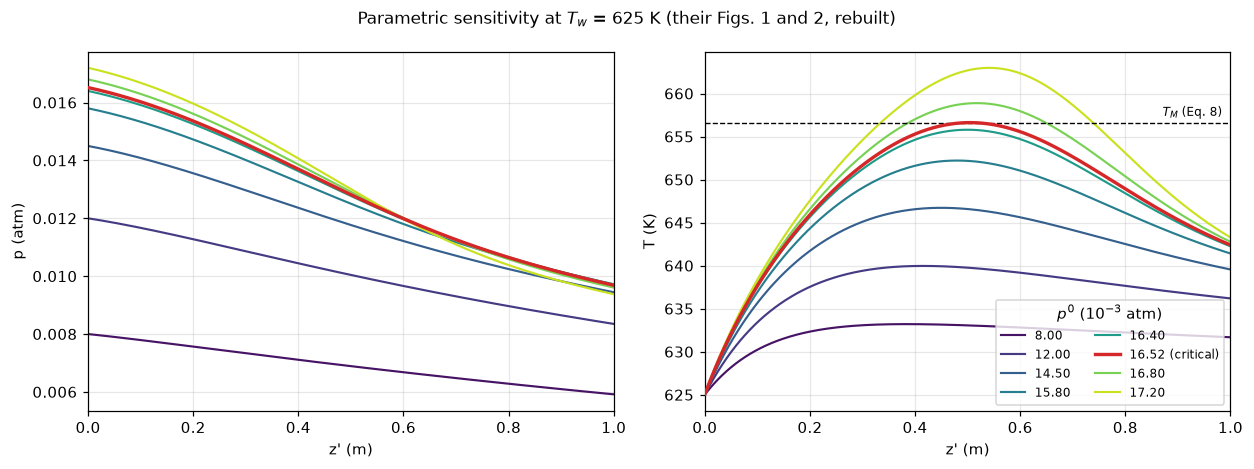

critical inlet partial pressure at Tw = 625 K, pymrm reactor: 0.01652 atm
paper, by back-integration from the critical point:      0.01651 atm


In [5]:
TM_625 = t_max_peak(CASE, TW)
CP_625 = critical_points(CASE, TW)
LO_625, UP_625, MEAN_625 = inlet_limits(CASE, TM_625, TW)
P_CRIT = critical_p0(CASE, TW, LO_625, MEAN_625)       # pymrm reactor, criterion 1
levels = [0.008, 0.012, 0.0145, 0.0158, 0.0164, P_CRIT, 0.0168, 0.0172]

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3))
cmap = plt.cm.viridis(np.linspace(0.05, 0.92, len(levels)))
tubes = {}
for p0, col in zip(levels, cmap):
    m = tubes[p0] = RunawayTube(CASE, p0, TW).solve()
    z_m = m.z_c * CASE.u                       # back to metres for the plot
    crit = p0 == P_CRIT
    kw = dict(color="tab:red" if crit else col, lw=2.2 if crit else 1.4,
              zorder=5 if crit else 2)
    axes[0].plot(z_m, m.p, **kw)
    axes[1].plot(z_m, m.T, label=f"{p0*1000:.2f}" + (" (critical)" if crit else ""),
                 **kw)
axes[0].set(xlabel="z' (m)", ylabel="p (atm)", xlim=(0, 1))
axes[1].set(xlabel="z' (m)", ylabel="T (K)", xlim=(0, 1))
axes[1].axhline(TM_625, color="k", ls="--", lw=0.9)
axes[1].text(0.985, TM_625 + 0.7, r"$T_M$ (Eq. 8)", fontsize=8, ha="right")
axes[1].legend(title=r"$p^0$ (10$^{-3}$ atm)", fontsize=8, loc="lower right",
               ncol=2)
fig.suptitle(f"Parametric sensitivity at $T_w$ = {TW:.0f} K "
             f"(their Figs. 1 and 2, rebuilt)", fontsize=11)
fig.tight_layout()
plt.show()

print(f"critical inlet partial pressure at Tw = {TW:.0f} K, pymrm reactor: {P_CRIT:.5f} atm")
print(f"paper, by back-integration from the critical point:      "
      f"{paper('1a', 'p0_critical'):.5f} atm")

The whole argument is easier to see in the *p*–*T* plane,
where the trajectories are inlet-independent geometry against two fixed
curves.

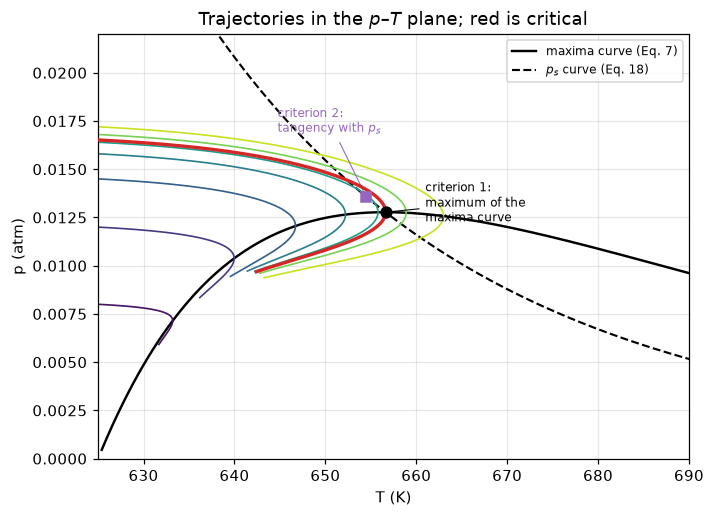

In [6]:
fig, ax = plt.subplots(figsize=(6.6, 4.8))
Tgrid = np.linspace(TW + 0.4, 700.0, 400)
ax.plot(Tgrid, maxima_curve(CASE, Tgrid, TW), "k-", lw=1.6, label="maxima curve (Eq. 7)")
ax.plot(Tgrid, ps_curve(CASE, Tgrid), "k--", lw=1.4, label=r"$p_s$ curve (Eq. 18)")

ax.plot([TM_625], [maxima_curve(CASE, TM_625, TW)], "ko", ms=7, zorder=6)
ax.annotate("criterion 1:\nmaximum of the\nmaxima curve",
            (TM_625, maxima_curve(CASE, TM_625, TW)), textcoords="offset points",
            xytext=(26, -6), fontsize=8,
            arrowprops=dict(arrowstyle="-", lw=0.7, color="k"))
Tt = CP_625["T2"]
ax.plot([Tt], [ps_curve(CASE, Tt)], "s", color="tab:purple", ms=7, zorder=6)
ax.annotate("criterion 2:\ntangency with $p_s$",
            (Tt, ps_curve(CASE, Tt)), textcoords="offset points",
            xytext=(-58, 42), fontsize=8, color="tab:purple",
            arrowprops=dict(arrowstyle="-", lw=0.7, color="tab:purple"))

for p0, col in zip(levels, cmap):
    m = tubes[p0]
    crit = p0 == P_CRIT
    ax.plot(m.T, m.p, color="tab:red" if crit else col,
            lw=2.2 if crit else 1.1, zorder=5 if crit else 2)
ax.set(xlabel="T (K)", ylabel="p (atm)", xlim=(TW, 690), ylim=(0, 0.022),
       title=r"Trajectories in the $p$–$T$ plane; red is critical")
ax.legend(fontsize=8, loc="upper right")
fig.tight_layout()
plt.show()

### The hot spot against the inlet pressure

The profiles above stop at 0.0172 atm, just past the critical value. Followed
further with `pymrm.continuation`, the hot spot shows what "runaway" means
here: no jump and no second solution, but a stretch of inlet pressure over which
it climbs by hundreds of kelvin, and beyond it a solution that is still bounded,
below the adiabatic temperature $T_w + (B/A)\,p^0$. The critical value of
criterion 1 is not where that stretch is: the steepest relative sensitivity,
$\mathrm{d}\ln T_{\max}/\mathrm{d}\ln p^0$, lies about 11 % higher in inlet
pressure (computed below). The criterion marks the start of the sensitive
region, with a margin, not the cliff.

The curve is on the page's 1500 cells. There the steep part is under-resolved
by a few kelvin: the hot spot at 0.0182 atm is 3.1 K and at 0.019 atm 2.7 K
below its value converged in the grid (Richardson from 12 000 and 24 000 cells),
against 0.04 K in the controlled region (Validation).

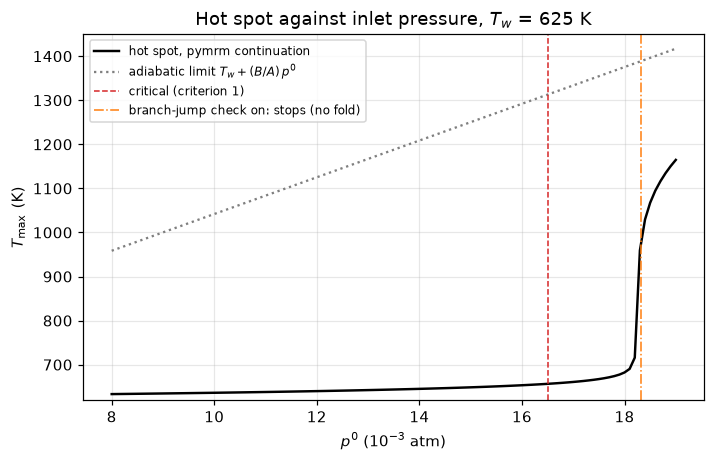

5 % more p0 from 0.0164 atm: hot spot +7.4 K on 1500 cells, +7.47 K converged
1 % more p0 from 0.0182 atm: hot spot +304 K on 1500 cells, +304 K converged
grid error of the hot spot on 1500 cells: 3.1 K at 0.0182 atm, 2.7 K at 0.019 atm
at p0 = 0.0190 atm the hot spot is 1165 K on 1500 cells (1167 K converged), below the adiabatic 1417 K
steepest d ln T_max / d ln p0 at 11 % above criterion 1's critical p0 (sampled every 1e-4 atm)
branch-jump check on, steps of 1e-4 atm: success = False; stopped at p = 0.0183234 on the way to 0.0184: the corrector jumps to another solution branch; probably a turning point (fold) of the solution branch
   (that fold does not exist) steps of 2e-5 atm from 0.018 to 0.019 atm: success = True


In [7]:
P_SWEEP = np.round(np.arange(0.008, 0.0190 + 1e-9, 1e-4), 6)
TRACE = RunawayTube(CASE, P_SWEEP[0], TW).trace_inlet(P_SWEEP)
assert TRACE.success, TRACE.message
HS_SWEEP = np.array([x[:, 1].max() for x in TRACE.xs])


def hot_spot(p0, Tw=TW, case=CASE, **kw):
    """Hot spot (K) of an independent solve from the inlet state."""
    return RunawayTube(case, p0, Tw, **kw).solve().hot_spot()


SENS_P = (0.0164, 0.0164 * 1.05, 0.0182, 0.0182 * 1.01, 0.0190)


def hot_spots(case=CASE, n_z=1500):
    """Hot spots at SENS_P on ``n_z`` cells."""
    return np.array([hot_spot(p, case=case, n_z=n_z) for p in SENS_P])


def converged_hot_spots(case=CASE):
    """Hot spots at SENS_P, Richardson-extrapolated from 12 000 and 24 000 cells."""
    h1, h2 = hot_spots(case, 12000), hot_spots(case, 24000)
    return h2 + (h2 - h1)


def sensitivity(hs):
    """Hot-spot rise for 5 % more p0 from 0.0164 atm and for 1 % more from 0.0182 atm."""
    return hs[1] - hs[0], hs[3] - hs[2]


def steepest_over_critical_pct(hs_sweep, p_crit=None):
    """Where d ln T_max / d ln p0 is largest along the sweep, % above the critical p0."""
    slope = np.gradient(np.log(hs_sweep), np.log(P_SWEEP))
    return (P_SWEEP[int(np.argmax(slope))] / (P_CRIT if p_crit is None else p_crit) - 1) * 100


HS_1500, HS_CONV = hot_spots(), converged_hot_spots()
DT_5PCT, DT_1PCT = sensitivity(HS_1500)
DT_5PCT_CONV, DT_1PCT_CONV = sensitivity(HS_CONV)
ERR_0182, ERR_0190 = HS_CONV[2] - HS_1500[2], HS_CONV[4] - HS_1500[4]
STEEP_PCT = steepest_over_critical_pct(HS_SWEEP)
HS_019 = HS_SWEEP[-1]
T_AD_019 = TW + CASE.B / CASE.A * P_SWEEP[-1]
# continuation with its branch-jump check on: steps of 1e-4 atm, and of 2e-5 atm
P_FINE = np.round(np.arange(0.0180, 0.0190 + 1e-9, 2e-5), 6)
TRACE_DEFAULT = RunawayTube(CASE, P_SWEEP[0], TW).trace_inlet(P_SWEEP, max_change=0.2)
TRACE_FINE = RunawayTube(CASE, P_FINE[0], TW).trace_inlet(P_FINE, max_change=0.2)

fig, ax = plt.subplots(figsize=(6.6, 4.3))
ax.plot(P_SWEEP * 1000, HS_SWEEP, "k-", lw=1.6, label="hot spot, pymrm continuation")
ax.plot(P_SWEEP * 1000, TW + CASE.B / CASE.A * P_SWEEP, ":", color="tab:gray",
        label=r"adiabatic limit $T_w + (B/A)\,p^0$")
ax.axvline(P_CRIT * 1000, color="tab:red", lw=1.0, ls="--", label="critical (criterion 1)")
if not TRACE_DEFAULT.success:
    ax.axvline(TRACE_DEFAULT.last_param * 1000, color="tab:orange", lw=1.0, ls="-.",
               label="branch-jump check on: stops (no fold)")
ax.set(xlabel=r"$p^0$ (10$^{-3}$ atm)", ylabel=r"$T_{\max}$ (K)", ylim=(620, 1450),
       title=f"Hot spot against inlet pressure, $T_w$ = {TW:.0f} K")
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

print(f"5 % more p0 from 0.0164 atm: hot spot +{DT_5PCT:.1f} K on 1500 cells, "
      f"+{DT_5PCT_CONV:.2f} K converged")
print(f"1 % more p0 from 0.0182 atm: hot spot +{DT_1PCT:.0f} K on 1500 cells, "
      f"+{DT_1PCT_CONV:.0f} K converged")
print(f"grid error of the hot spot on 1500 cells: {ERR_0182:.1f} K at 0.0182 atm, "
      f"{ERR_0190:.1f} K at 0.019 atm")
print(f"at p0 = {P_SWEEP[-1]:.4f} atm the hot spot is {HS_019:.0f} K on 1500 cells "
      f"({HS_CONV[4]:.0f} K converged), below the adiabatic {T_AD_019:.0f} K")
print(f"steepest d ln T_max / d ln p0 at {STEEP_PCT:.0f} % above criterion 1's critical "
      f"p0 (sampled every 1e-4 atm)")
print(f"branch-jump check on, steps of 1e-4 atm: success = {TRACE_DEFAULT.success}; "
      f"{TRACE_DEFAULT.message}")
print(f"   (that fold does not exist) steps of 2e-5 atm from 0.018 to 0.019 atm: "
      f"success = {TRACE_FINE.success}")

### The runaway boundary across wall temperatures (their Fig. 8)

Their Fig. 8 gives the critical inlet pressure against the wall temperature:
four curves (the two criteria's brackets) through a handful of points, because
each exact value cost a numerical back-integration. Here each criterion's exact
value is the same back-integration, at 21 wall temperatures, and the
interesting quantity is not the boundary itself but the *width of the bracket*,
which is the price of not integrating.

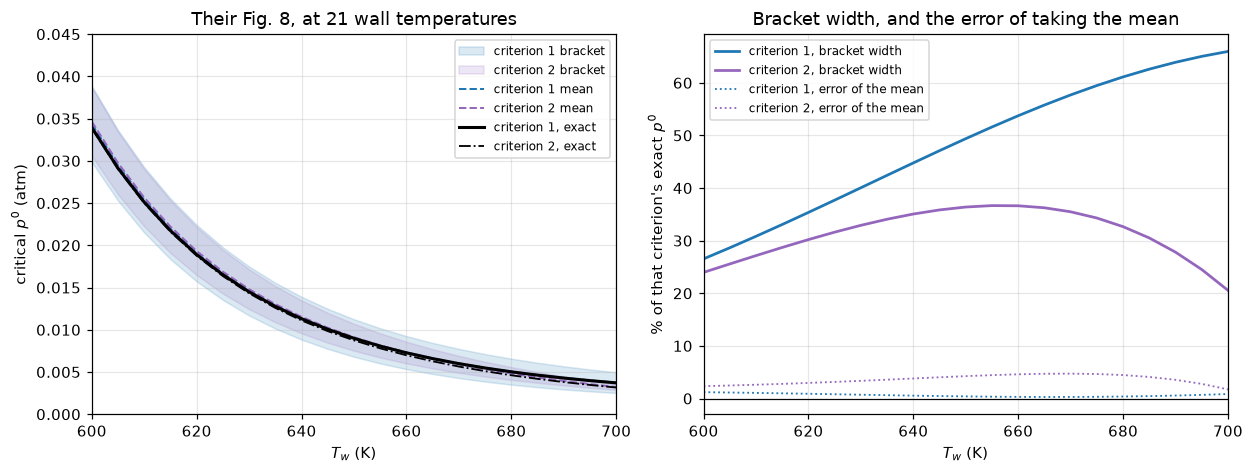

bracket width, as a percentage of that criterion's own exact critical p0:
   criterion 1: 26.5 % to 66.0 %
   criterion 2: 20.6 % to 36.7 %
error of the mean, as a percentage of that criterion's own exact value:
   criterion 1: +0.29 % to +1.21 %
   criterion 2: +1.73 % to +4.73 %
criterion 2's bracket is the narrower at every wall temperature: True
criterion 2's exact critical p0 is the lower at every wall temperature: True, by 0.3 % at 600 K and 14.8 % at 700 K
criterion 1's mean is the closer to its exact value at every wall temperature: True
at Tw = 625 K: error of the mean +0.81 % (criterion 1) and +3.16 % (criterion 2); exact values 0.93 % apart


In [8]:
TW_SWEEP = np.arange(600.0, 701.0, 5.0)


def criteria_sweep(case=CASE, limits=inlet_limits, tangency=t_tangency):
    """Brackets, means and exact (back-integrated) inlet pressures of both criteria.

    Each criterion has its own critical trajectory and therefore its own exact
    inlet pressure; comparing both against criterion 1's would flatter one of them.
    """
    out = {k: [] for k in ("lo1", "up1", "m1", "ex1", "lo2", "up2", "m2", "ex2")}
    for T in TW_SWEEP:
        T1 = t_max_peak(case, T)
        T2 = tangency(case, T)
        for i, Tc, pc in ((1, T1, maxima_curve(case, T1, T)), (2, T2, ps_curve(case, T2))):
            lo, up, mean = limits(case, Tc, T)
            out[f"lo{i}"].append(lo)
            out[f"up{i}"].append(up)
            out[f"m{i}"].append(mean)
            out[f"ex{i}"].append(back_integrate(case, Tc, pc, T))
    s = {k: np.array(v) for k, v in out.items()}
    s["w1"] = (s["up1"] - s["lo1"]) / s["ex1"] * 100       # bracket width, % of own exact
    s["w2"] = (s["up2"] - s["lo2"]) / s["ex2"] * 100
    s["e1"] = (s["m1"] / s["ex1"] - 1) * 100                # error of the mean, %
    s["e2"] = (s["m2"] / s["ex2"] - 1) * 100
    s["cons"] = (1 - s["ex2"] / s["ex1"]) * 100             # criterion 2 below criterion 1, %
    return s


SW = criteria_sweep()
I625 = int(np.argmin(abs(TW_SWEEP - TW)))

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
ax = axes[0]
ax.fill_between(TW_SWEEP, SW["lo1"], SW["up1"], color="tab:blue", alpha=0.16,
                label="criterion 1 bracket")
ax.fill_between(TW_SWEEP, SW["lo2"], SW["up2"], color="tab:purple", alpha=0.16,
                label="criterion 2 bracket")
ax.plot(TW_SWEEP, SW["m1"], color="tab:blue", lw=1.3, ls="--", label="criterion 1 mean")
ax.plot(TW_SWEEP, SW["m2"], color="tab:purple", lw=1.3, ls="--", label="criterion 2 mean")
ax.plot(TW_SWEEP, SW["ex1"], color="k", lw=2.0, label="criterion 1, exact")
ax.plot(TW_SWEEP, SW["ex2"], color="k", lw=1.2, ls="-.", label="criterion 2, exact")
ax.set(xlabel=r"$T_w$ (K)", ylabel=r"critical $p^0$ (atm)", xlim=(600, 700),
       ylim=(0, 0.045), title="Their Fig. 8, at 21 wall temperatures")
ax.legend(fontsize=8)

ax = axes[1]
ax.plot(TW_SWEEP, SW["w1"], color="tab:blue", lw=1.8, label="criterion 1, bracket width")
ax.plot(TW_SWEEP, SW["w2"], color="tab:purple", lw=1.8, label="criterion 2, bracket width")
ax.plot(TW_SWEEP, SW["e1"], color="tab:blue", lw=1.2, ls=":",
        label="criterion 1, error of the mean")
ax.plot(TW_SWEEP, SW["e2"], color="tab:purple", lw=1.2, ls=":",
        label="criterion 2, error of the mean")
ax.axhline(0.0, color="k", lw=0.8)
ax.set(xlabel=r"$T_w$ (K)", ylabel="% of that criterion's exact $p^0$",
       xlim=(600, 700), title="Bracket width, and the error of taking the mean")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

print("bracket width, as a percentage of that criterion's own exact critical p0:")
for lbl, w in (("criterion 1", SW["w1"]), ("criterion 2", SW["w2"])):
    print(f"   {lbl}: {w.min():.1f} % to {w.max():.1f} %")
print("error of the mean, as a percentage of that criterion's own exact value:")
for lbl, e in (("criterion 1", SW["e1"]), ("criterion 2", SW["e2"])):
    print(f"   {lbl}: {e.min():+.2f} % to {e.max():+.2f} %")
print(f"criterion 2's bracket is the narrower at every wall temperature: "
      f"{bool(np.all(SW['w2'] < SW['w1']))}")
print(f"criterion 2's exact critical p0 is the lower at every wall temperature: "
      f"{bool(np.all(SW['cons'] > 0))}, by {SW['cons'][0]:.1f} % at 600 K and "
      f"{SW['cons'][-1]:.1f} % at 700 K")
print(f"criterion 1's mean is the closer to its exact value at every wall temperature: "
      f"{bool(np.all(abs(SW['e1']) < abs(SW['e2'])))}")
print(f"at Tw = 625 K: error of the mean {SW['e1'][I625]:+.2f} % (criterion 1) and "
      f"{SW['e2'][I625]:+.2f} % (criterion 2); exact values {SW['cons'][I625]:.2f} % apart")

### Their Fig. 7, recomputed

Both of their Figs. 6 and 7 are graphical solutions of one implicit equation,
Eq. 20, and the paper says as much: the figures are there "to facilitate the
solution of (20)". Solving it directly turns them from *inputs* into *checks*.
The curve below is their Fig. 7 recomputed rather than read, and their $t_r$ in
Example 1(b) is a value they took off that graph by eye.

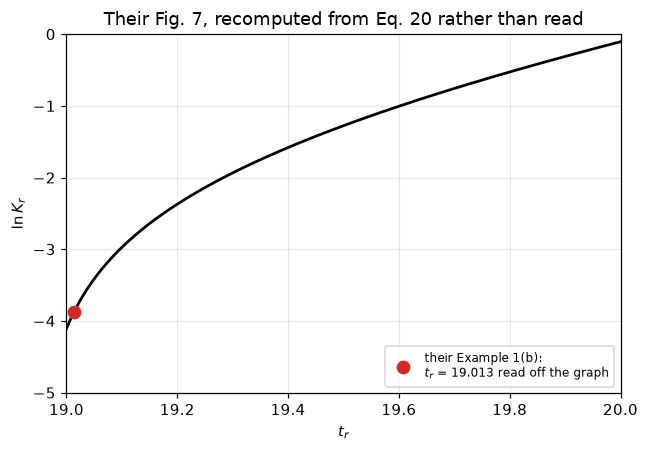

t from solving Eq. 20 directly : 20.8347   their graphical value 20.831
t_r equivalent                 : 19.0171   their 19.013
(T_i)_t                        : 654.48 K   their 654.6 K


In [9]:
tr = np.linspace(19.0, 20.0, 240)


def lnK_at(t, tw):
    return np.log((t - 2.0) / (t * np.exp(-t + 20.0)) * (1.0 - t * (1.0 - t / tw)))


K_625 = CASE.A / CASE.C * np.exp(CASE.b - 20.0)
fig, ax = plt.subplots(figsize=(6.0, 4.2))
ax.plot(tr, lnK_at(tr, 20.0), "k-", lw=1.8)
ax.plot([paper("1b", "t_r")], [np.log(K_625) - (CASE.a / TW - 20.0)], "o", color="tab:red",
        ms=8, label=f"their Example 1(b):\n$t_r$ = {paper('1b', 't_r')} read off the graph")
ax.set(xlabel=r"$t_r$", ylabel=r"$\ln K_r$", xlim=(19.0, 20.0), ylim=(-5, 0),
       title="Their Fig. 7, recomputed from Eq. 20 rather than read")
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
plt.show()

t_direct = CASE.a / CP_625["T2"]
print(f"t from solving Eq. 20 directly : {t_direct:.4f}   their graphical value "
      f"{paper('1b', 't')}")
print(f"t_r equivalent                 : {t_direct - (CASE.a / TW - 20.0):.4f}"
      f"   their {paper('1b', 't_r')}")
print(f"(T_i)_t                        : {CP_625['T2']:.2f} K   their {paper('1b', 'T_cr')} K")

## Validation

Five checks, in increasing order of how much of the page they exercise, then the
claims and the break table.

In [10]:
# 1. Does the parameter reading survive contact with the paper's own derived
#    quantities? Each of these depends on the whole table at once, and none was
#    used to obtain it, so a single mis-set decimal point breaks all of them.
print("1. Parameter reading, against derived values printed in the paper")
checks = [("ln K (Eq. 22)", np.log(K_625), paper("1b", "ln_K")),
          ("t_w (Eq. 21b)", CASE.a / TW, paper("1b", "t_w")),
          ("T_M (Eq. 8)", TM_625, paper("1a", "T_cr"))]
for name, val, ref in checks:
    print(f"   {name:<16} {val:>14.6g}   paper {ref:>8}   "
          f"rel {abs(val - ref) / abs(ref) * 100:5.2f} %")


def identity_gap(Tm, Tw=TW, a=CASE.a):
    """Relative gap of T_M^2 = a (T_M - T_w), which Eq. 8 makes exact."""
    return abs(Tm ** 2 - a * (Tm - Tw)) / Tm ** 2


ID_GAP = identity_gap(TM_625)
print(f"   identity T_M^2 = a(T_M - T_w), the reason Eqs. 27 and 29 agree at T_M: "
      f"relative gap below 1e-12 (here {ID_GAP:.0e})")

1. Parameter reading, against derived values printed in the paper
   ln K (Eq. 22)          -2.05685   paper   -2.055   rel  0.09 %
   t_w (Eq. 21b)           21.8176   paper   21.818   rel  0.00 %
   T_M (Eq. 8)             656.618   paper    656.6   rel  0.00 %
   identity T_M^2 = a(T_M - T_w), the reason Eqs. 27 and 29 agree at T_M: relative gap below 1e-12 (here 2e-15)


In [11]:
# 2. Grid independence. First-order upwind, so successive differences halve.
GRID_NS = (200, 400, 800, 1600, 3200)


def grid_study(ns=GRID_NS, case=CASE, p0=0.0164):
    """Hot spots on the grids ``ns``, the observed order of the last three, and the
    Richardson estimate of the error at the default n_z = 1500."""
    vals = [hot_spot(p0, case=case, n_z=n) for n in ns]
    order = np.log2((vals[-2] - vals[-3]) / (vals[-1] - vals[-2]))
    richardson = vals[-1] + (vals[-1] - vals[-2])
    return vals, order, abs(richardson - hot_spot(p0, case=case)), richardson


GRID_VALS, GRID_ORDER, ERR_1500, RICH = grid_study()
print("2. Grid independence: hot spot at Tw = 625 K, p0 = 0.0164 atm")
for i, (n, v) in enumerate(zip(GRID_NS, GRID_VALS)):
    print(f"   n_z = {n:5d}   T_max = {v:.5f} K"
          + ("" if i == 0 else f"   change {v - GRID_VALS[i - 1]:+.2e}"))
print(f"   observed order {GRID_ORDER:.3f}; Richardson estimate {RICH:.5f} K; "
      f"error at n_z = 1500 is about {ERR_1500:.1e} K")

2. Grid independence: hot spot at Tw = 625 K, p0 = 0.0164 atm
   n_z =   200   T_max = 655.53181 K
   n_z =   400   T_max = 655.68022 K   change +1.48e-01
   n_z =   800   T_max = 655.75531 K   change +7.51e-02
   n_z =  1600   T_max = 655.79307 K   change +3.78e-02
   n_z =  3200   T_max = 655.81202 K   change +1.89e-02
   observed order 0.996; Richardson estimate 655.83096 K; error at n_z = 1500 is about 4.0e-02 K


In [12]:
# 3. The four worked examples, one by one. `kind` separates the values that
#    test the closed-form criteria from those that test the ODE solve.


def examples(case=CASE):
    """Every value printed in Section 6, recomputed for ``case``, beside the paper's."""
    rows = []

    def rec(example, quantity, computed):
        hit = ex[(ex.example == example) & (ex.quantity == quantity)]
        if hit.empty:
            return
        ref = float(hit.value.iloc[0])
        rows.append({"example": example, "quantity": quantity, "kind": hit.kind.iloc[0],
                     "paper": ref, "computed": computed,
                     "rel_pct": abs(computed - ref) / abs(ref) * 100})

    A, B, C, a, b = case.A, case.B, case.C, case.a, case.b
    # Example 1(a): first criterion
    TM = t_max_peak(case, TW)
    lo1, up1, mean1 = inlet_limits(case, TM, TW)
    cp = critical_points(case, TW)
    for q, v in (("T_cr", TM), ("p0_lower", lo1), ("p0_upper", up1), ("p0_mean", mean1),
                 ("p0_critical", cp["p0_1"])):
        rec("1a", q, v)
    # Example 1(b): second criterion, solving Eq. 20 instead of reading Figs. 6-7
    K = A / C * np.exp(b - 20.0)
    Tt = cp["T2"]
    lo2, up2, mean2 = inlet_limits(case, Tt, TW)
    for q, v in (("t_w", a / TW), ("ln_K", np.log(K)), ("delta_t", a / TW - 20.0),
                 ("ln_K_r", np.log(K) - (a / TW - 20.0)), ("t", a / Tt),
                 ("t_r", a / Tt - (a / TW - 20.0)), ("T_cr", Tt), ("p0_lower", lo2),
                 ("p0_upper", up2), ("p0_mean", mean2), ("p0_critical", cp["p0_2"])):
        rec("1b", q, v)
    # Example 2: subcritical, an imposed hot spot of 640 K
    Tm2 = 640.0
    X2 = A / C * kexp(case, Tm2)
    p_m2 = A / B * (Tm2 - TW) * (1.0 + 1.0 / np.sqrt(X2) + 1.0 / X2)     # Eq. 30
    rec("2", "p0_mean", p_m2)
    rec("2", "p0_exact", back_integrate(case, Tm2, maxima_curve(case, Tm2, TW), TW))
    rec("2", "T_max", hot_spot(p_m2, case=case))
    # Example 3: given p0 and an imposed hot spot, find the wall temperature
    p0_3, Tm3 = 0.0075, 675.0
    dT_ad3 = B / A * p0_3                                                # Eq. 32
    Q3 = 1.0 / np.sqrt(A / C * kexp(case, Tm3))                          # Eq. 34
    dT_eff3 = dT_ad3 / (1.0 + Q3 + Q3 ** 2)                              # Eq. 31
    Tw3 = Tm3 - dT_eff3                                                  # Eq. 33
    for q, v in (("dT_ad", dT_ad3), ("Q", Q3), ("dT_eff", dT_eff3), ("T_w", Tw3),
                 ("T_max", hot_spot(p0_3, Tw=Tw3, case=case))):
        rec("3", q, v)
    # Example 4: given p0 and Tw, find the radius that is critical
    p0_4 = 0.0125
    dT_ad4 = B / A * p0_4
    dT_eff4 = TM - TW
    Q4 = brentq(lambda q: 1.0 + q + q * q - dT_ad4 / dT_eff4, 0.0, 1e3)
    C4 = Q4 ** 2 * A * kexp(case, TM)
    for q, v in (("T_cr", TM), ("dT_eff", dT_eff4), ("dT_ad", dT_ad4), ("Q", Q4),
                 ("C", C4), ("R", 2.0 * case.U / (case.c_p * C4))):
        rec("4", q, v)
    return pd.DataFrame(rows)


def example_stats(comp):
    """Mean and worst relative deviation (%), overall and per kind."""
    return dict(mean=comp.rel_pct.mean(), worst=comp.rel_pct.max(),
                criterion=comp[comp.kind == "criterion"].rel_pct.mean(),
                integration=comp[comp.kind == "integration"].rel_pct.mean())


COMP = examples()
EXS = example_stats(COMP)
print("3. The four worked examples of Section 6\n" + COMP.to_string(index=False, formatters={
    "paper": "{:.5g}".format, "computed": "{:.5g}".format, "rel_pct": "{:.3f}".format}))
for kind, sub in COMP.groupby("kind"):
    print(f"   {kind:<11}: n = {len(sub):2d}   mean |dev| = {sub.rel_pct.mean():.3f} %"
          f"   worst = {sub.rel_pct.max():.3f} % ({sub.loc[sub.rel_pct.idxmax(), 'quantity']})")
print(f"   overall    : n = {len(COMP):2d}   mean |dev| = {EXS['mean']:.3f} %"
      f"   worst = {EXS['worst']:.3f} %")

3. The four worked examples of Section 6
example    quantity        kind   paper computed rel_pct
     1a        T_cr   criterion   656.6   656.62   0.003
     1a    p0_lower   criterion 0.01353 0.013532   0.016
     1a    p0_upper   criterion 0.01976 0.019757   0.013
     1a     p0_mean   criterion 0.01665 0.016645   0.031
     1a p0_critical integration 0.01651 0.016511   0.005
     1b         t_w   criterion  21.818   21.818   0.002
     1b        ln_K   criterion  -2.055  -2.0568   0.090
     1b     delta_t   criterion  1.8176   1.8176   0.000
     1b      ln_K_r   criterion  -3.873  -3.8744   0.037
     1b           t   criterion  20.831   20.835   0.018
     1b         t_r   criterion  19.013   19.017   0.022
     1b        T_cr   criterion   654.6   654.48   0.018
     1b    p0_lower   criterion 0.01423 0.014287   0.400
     1b    p0_upper   criterion 0.01948 0.019458   0.111
     1b     p0_mean   criterion 0.01686 0.016873   0.075
     1b p0_critical integration 0.01641 0.01635

In [13]:
# 4. Two independent routes to the same critical inlet pressure. The pymrm
#    reactor discretises the tube in z and its hot spot is root-found against
#    T_M; the back-integration is a quadrature in the p-T plane with an adaptive
#    Runge-Kutta and never forms the reactor grid at all. They should agree, and
#    they are the only pair of numbers on this page that does not involve the
#    paper. Bisection on the same bracket is a second route to the reactor value.
TW_CROSS = np.arange(600.0, 701.0, 20.0)


def cross_check(n_z=1500, bisect_tol=1e-7, case=CASE):
    """Per wall temperature: back-integrated and reactor critical p0, the
    bracket of Eqs. 27 and 30, and the reactor value by bisection."""
    rows = []
    for T in TW_CROSS:
        cpts = critical_points(case, T)
        lo, up, mean = inlet_limits(case, cpts["T1"], T)
        root = critical_p0(case, T, lo, mean, n_z=n_z)
        rows.append(dict(Tw=T, back=cpts["p0_1"], reactor=root,
                         bisect=critical_p0_bisect(case, T, lo, mean, tol=bisect_tol, n_z=n_z),
                         lower=lo, upper=up))
    df = pd.DataFrame(rows)
    df["rel_pct"] = (df.reactor - df.back).abs() / df.back * 100
    return df


CROSS = cross_check()
CROSS_WORST = CROSS.rel_pct.max()
BISECT_GAP = (CROSS.bisect - CROSS.reactor).abs().max()
BRACKETED = bool(((CROSS.lower <= CROSS.back) & (CROSS.back <= CROSS.upper)).all())
P_CRIT_REL_MARGIN = float(np.minimum((CROSS.back - CROSS.lower) / CROSS.back,
                                     (CROSS.upper - CROSS.back) / CROSS.back).min())
print("4. pymrm reactor root vs phase-plane back-integration (criterion 1)")
for r in CROSS.itertuples():
    print(f"   Tw = {r.Tw:.0f} K:  back-integration {r.back:.5f}   pymrm {r.reactor:.5f}   "
          f"{r.rel_pct:5.2f} %   inside its bracket: {r.lower <= r.back <= r.upper}")
print(f"   worst disagreement between the two methods: {CROSS_WORST:.2f} %")
print(f"   criterion 1 brackets its own critical value everywhere: {BRACKETED}")
print(f"   bisection to 1e-7 atm against the root: below 1e-7 atm "
      f"(here {BISECT_GAP:.0e} atm)")

4. pymrm reactor root vs phase-plane back-integration (criterion 1)
   Tw = 600 K:  back-integration 0.03395   pymrm 0.03396    0.02 %   inside its bracket: True
   Tw = 620 K:  back-integration 0.01890   pymrm 0.01891    0.03 %   inside its bracket: True
   Tw = 640 K:  back-integration 0.01131   pymrm 0.01132    0.05 %   inside its bracket: True
   Tw = 660 K:  back-integration 0.00727   pymrm 0.00728    0.08 %   inside its bracket: True
   Tw = 680 K:  back-integration 0.00502   pymrm 0.00503    0.13 %   inside its bracket: True
   Tw = 700 K:  back-integration 0.00371   pymrm 0.00372    0.18 %   inside its bracket: True
   worst disagreement between the two methods: 0.18 %
   criterion 1 brackets its own critical value everywhere: True
   bisection to 1e-7 atm against the root: below 1e-7 atm (here 3e-08 atm)


In [14]:
# 5. The continuation sweep against independent solves from the inlet state.
def trace_gap(trace=TRACE, n_z=1500):
    """Largest temperature gap (K), over every cell and every traced point,
    between the sweep and independent solves from the inlet state."""
    return max(float(np.max(abs(x[:, 1] - RunawayTube(CASE, p, TW, n_z=n_z).solve().T)))
               for p, x in zip(trace.params, trace.xs))


TRACE_GAP = trace_gap()
print(f"5. Continuation against independent solves at all {len(P_SWEEP)} inlet pressures")
print(f"   largest temperature gap over all cells below 1e-6 K (here {TRACE_GAP:.0e} K)")

5. Continuation against independent solves at all 111 inlet pressures
   largest temperature gap over all cells below 1e-6 K (here 3e-09 K)


### Claims: what each number is, and how it is checked

Every number the page stands behind is registered once, in the cell below
(`docs/claims-design.md` in the gallery repository):

- a **value** is a result whose size is set by physics, the data or the
  discretisation. CI holds it to a relative tolerance of the committed
  baseline, 5 % unless the cell says otherwise. Closed-form and root-found
  values carry tighter tolerances, set by their solver tolerances;
- a **bound** is a quantity whose size is not physics: an identity, a
  solver-tolerance gap, a convergence order. It is checked against its stated
  limits on every run and states its basis;
- an **exact** result is a count or a label, with its distance to the
  threshold that decided it.

In [15]:
# --- the worked examples ------------------------------------------------------
claims.value("examples_mean_dev_pct", EXS["mean"])
claims.value("examples_worst_dev_pct", EXS["worst"])
claims.value("criterion_mean_dev_pct", EXS["criterion"])
claims.value("integration_mean_dev_pct", EXS["integration"])
for name, n in (("n_examples", len(COMP)),
                ("n_examples_criterion", int((COMP.kind == "criterion").sum())),
                ("n_examples_integration", int((COMP.kind == "integration").sum()))):
    claims.exact(name, n, structural=True,
                 note="rows of the examples CSV that the page recomputes; set by the data")
# --- criterion 1 at 625 K ---------------------------------------------------------
claims.value("T_M_at_625K", TM_625, rtol=1e-9, unit="K")
claims.bound("tm_identity_rel", ID_GAP, max=1e-12, basis="identity",
             note="T_M^2 = a (T_M - T_w) follows from Eq. 8")
claims.value("p0_critical_at_625K", CP_625["p0_1"], rtol=1e-6, unit="atm",
             note="back-integration, solve_ivp rtol 1e-11")
claims.value("p0_critical_reactor_625K", P_CRIT, rtol=1e-6, unit="atm",
             note="brentq to 1e-12 atm on Newton solves at tol 1e-10 (scaled)")
# --- two routes, and the bisection ---------------------------------------------------
claims.value("cross_method_worst_pct", CROSS_WORST)
claims.bound("bisection_vs_root_atm", BISECT_GAP, max=1e-7, basis="tolerance",
             unit="atm", note="bisection to a bracket narrower than 1e-7 atm")
claims.exact("criterion1_brackets_exact", BRACKETED, margin=P_CRIT_REL_MARGIN,
             min_margin=0.01,
             note="margin: smallest distance of the exact value to an end of its bracket, "
                  "relative to the exact value")
# --- the grid ----------------------------------------------------------------------------
claims.bound("hotspot_grid_order", GRID_ORDER, min=0.9, max=1.1, basis="theory",
             note="first-order upwind, n_z 800, 1600, 3200")
claims.value("hotspot_error_n1500_K", ERR_1500, unit="K",
             note="Richardson estimate from n_z = 1600 and 3200")
# --- sensitivity and the continuation sweep ---------------------------------------------
claims.value("dT_hotspot_5pct_from_0164_K", DT_5PCT, unit="K", note="1500 cells")
claims.value("dT_hotspot_5pct_converged_K", DT_5PCT_CONV, unit="K",
             note="Richardson from 12000 and 24000 cells")
claims.value("dT_hotspot_1pct_converged_K", DT_1PCT_CONV, unit="K",
             note="Richardson from 12000 and 24000 cells")
claims.value("hotspot_grid_err_0182_K", ERR_0182, unit="K", note="1500 cells against converged")
claims.value("hotspot_grid_err_0190_K", ERR_0190, unit="K", note="1500 cells against converged")
claims.value("hotspot_0190_converged_K", HS_CONV[4], unit="K")
claims.value("steepest_sensitivity_above_crit_pct", STEEP_PCT, rtol=0.1,
             note="argmax on the 1e-4 atm sweep: rtol covers one sample spacing")
claims.exact("check_on_fine_steps_succeeds", TRACE_FINE.success,
             note="branch-jump check on, steps of 2e-5 atm")
claims.value("dT_hotspot_1pct_from_0182_K", DT_1PCT, unit="K")
claims.value("hotspot_p0190_K", HS_019, unit="K")
claims.bound("trace_vs_independent_K", TRACE_GAP, max=1e-6, basis="tolerance", unit="K",
             note="newton tol 1e-10 on the scaled unknowns in both")
claims.exact("default_branch_check_stops", not TRACE_DEFAULT.success,
             note="continuation with max_change = 0.2 over the same sweep")
# --- the Fig. 8 sweep --------------------------------------------------------------------
claims.value("bracket_width_c1_min_pct", SW["w1"].min())
claims.value("bracket_width_c1_max_pct", SW["w1"].max())
claims.value("bracket_width_c2_min_pct", SW["w2"].min())
claims.value("bracket_width_c2_max_pct", SW["w2"].max())
claims.value("mean_error_c1_min_pct", SW["e1"].min())
claims.value("mean_error_c1_max_pct", SW["e1"].max())
claims.value("mean_error_c2_min_pct", SW["e2"].min())
claims.value("mean_error_c2_max_pct", SW["e2"].max())
claims.value("c2_below_c1_600K_pct", SW["cons"][0])
claims.value("c2_below_c1_700K_pct", SW["cons"][-1])
claims.value("mean_error_c1_625K_pct", SW["e1"][I625])
claims.value("mean_error_c2_625K_pct", SW["e2"][I625])
claims.value("c2_below_c1_625K_pct", SW["cons"][I625])
claims.exact("c2_bracket_narrower_everywhere", bool(np.all(SW["w2"] < SW["w1"])),
             margin=float((SW["w1"] - SW["w2"]).min()), min_margin=0.5,
             note="margin in percentage points of the criterion's own exact p0")
claims.exact("c2_more_conservative_everywhere", bool(np.all(SW["cons"] > 0)),
             margin=float(SW["cons"].min()), min_margin=0.05, note="margin in percent")
claims.exact("c1_mean_closer_everywhere", bool(np.all(abs(SW["e1"]) < abs(SW["e2"]))),
             margin=float((abs(SW["e2"]) - abs(SW["e1"])).min()), min_margin=0.1,
             note="margin in percentage points")

# prose numbers
claims.says("7.4", "dT_hotspot_5pct_from_0164_K")      # Background
claims.says("7.47", "dT_hotspot_5pct_converged_K")
claims.says("304", "dT_hotspot_1pct_converged_K")
claims.says("11", "steepest_sensitivity_above_crit_pct")  # "about 11 % higher"
claims.says("3.1", "hotspot_grid_err_0182_K")
claims.says("2.7", "hotspot_grid_err_0190_K")
claims.says("304", "dT_hotspot_1pct_from_0182_K")      # Background
claims.says("27", "bracket_width_c1_min_pct")          # What pymrm adds: "27 % to 66 %"
claims.says("66", "bracket_width_c1_max_pct")
claims.says("21", "bracket_width_c2_min_pct")          # "21 % to 37 %"
claims.says("37", "bracket_width_c2_max_pct")
claims.says("0.3", "c2_below_c1_600K_pct")             # "0.3 % at 600 K"
claims.says("15", "c2_below_c1_700K_pct")              # "15 % at 700 K"
claims.says("0.3", "mean_error_c1_min_pct")            # "+0.3 % to +1.2 %"
claims.says("1.2", "mean_error_c1_max_pct")
claims.says("1.7", "mean_error_c2_min_pct")            # "+1.7 % to +4.7 %"
claims.says("4.7", "mean_error_c2_max_pct")
claims.says("0.8", "mean_error_c1_625K_pct")           # "0.8 % ... 3.2 %"
claims.says("3.2", "mean_error_c2_625K_pct")
claims.says("0.9", "c2_below_c1_625K_pct")             # "differ by 0.9 %"
claims.says("0.18", "cross_method_worst_pct")          # What pymrm adds

True

### The defect-injection table

Each row breaks one thing on purpose, **re-runs** the computation behind one
claim with the defect in place, and hands the result to `claims.breaks`, which
records whether the claim's own check (its tolerance or its bound) catches it.
The first row is the units trap of this paper. Every claim that is not
structural must be failed by at least one row, and the last cell of the page
raises otherwise.

In [16]:
BREAK = []


def brk(name, metric, value, note=""):
    """One injected defect: ``value`` is what claim ``metric`` becomes with it."""
    caught = claims.breaks(name, metric, value)
    clean = claims[metric]
    if claims.metrics[metric]["kind"] == "bound":
        clean = f"(here {clean:.3g})"      # a bound's own value is not published: masked
    BREAK.append(dict(defect=name, metric=metric, clean=clean, broken=value,
                      caught=caught, note=note))


# --- the units trap: c_p multiplied by rho_g ------------------------------------------
TRAP = "c_p multiplied by rho_g (the units trap)"
CASE_TRAP = replace(CASE, c_p=CASE.c_p * CASE.rho_g)
_exs = example_stats(examples(CASE_TRAP))
for k, metric in (("mean", "examples_mean_dev_pct"), ("worst", "examples_worst_dev_pct"),
                  ("criterion", "criterion_mean_dev_pct"),
                  ("integration", "integration_mean_dev_pct")):
    brk(TRAP, metric, _exs[k])
brk(TRAP, "p0_critical_at_625K", critical_points(CASE_TRAP, TW)["p0_1"])
_lo, _up, _mean = inlet_limits(CASE_TRAP, TM_625, TW)
brk(TRAP, "p0_critical_reactor_625K", critical_p0(CASE_TRAP, TW, _lo, _mean))
_hs_trap, _hs_conv_trap = hot_spots(CASE_TRAP), converged_hot_spots(CASE_TRAP)
_dt5, _dt1 = sensitivity(_hs_trap)
brk(TRAP, "dT_hotspot_5pct_from_0164_K", _dt5)
brk(TRAP, "dT_hotspot_1pct_from_0182_K", _dt1)
_dt5c, _dt1c = sensitivity(_hs_conv_trap)
brk(TRAP, "dT_hotspot_5pct_converged_K", _dt5c)
brk(TRAP, "dT_hotspot_1pct_converged_K", _dt1c)
brk(TRAP, "hotspot_grid_err_0182_K", _hs_conv_trap[2] - _hs_trap[2])
brk(TRAP, "hotspot_grid_err_0190_K", _hs_conv_trap[4] - _hs_trap[4])
brk(TRAP, "hotspot_0190_converged_K", _hs_conv_trap[4])
brk(TRAP, "hotspot_error_n1500_K", grid_study(case=CASE_TRAP)[2])
_sw_trap = criteria_sweep(CASE_TRAP)
for metric, val in (("c2_below_c1_600K_pct", _sw_trap["cons"][0]),
                    ("c2_below_c1_700K_pct", _sw_trap["cons"][-1]),
                    ("mean_error_c1_625K_pct", _sw_trap["e1"][I625]),
                    ("mean_error_c2_625K_pct", _sw_trap["e2"][I625]),
                    ("c2_below_c1_625K_pct", _sw_trap["cons"][I625]),
                    ("bracket_width_c1_min_pct", _sw_trap["w1"].min()),
                    ("bracket_width_c2_min_pct", _sw_trap["w2"].min()),
                    ("mean_error_c2_min_pct", _sw_trap["e2"].min()),
                    ("c1_mean_closer_everywhere",
                     bool(np.all(abs(_sw_trap["e1"]) < abs(_sw_trap["e2"]))))):
    brk(TRAP, metric, val)
_trace_trap = RunawayTube(CASE_TRAP, P_SWEEP[0], TW).trace_inlet(P_SWEEP)
assert _trace_trap.success, _trace_trap.message
brk(TRAP, "hotspot_p0190_K", _trace_trap.xs[-1][:, 1].max())
brk("critical p0 taken as the Eq. 28 upper limit", "steepest_sensitivity_above_crit_pct",
    steepest_over_critical_pct(HS_SWEEP, UP_625))


# --- the criteria ------------------------------------------------------------------------
def _t_max_peak_plus(case, Tw):
    """Eq. 8 with the other root of the quadratic."""
    return 0.5 * (case.a + np.sqrt(case.a * (case.a - 4.0 * Tw)))


def _t_max_peak_typo(case, Tw):
    """Eq. 8 with 2 T_w instead of 4 T_w under the root."""
    return 0.5 * (case.a - np.sqrt(case.a * (case.a - 2.0 * Tw)))


brk("Eq. 8 with the other root of the quadratic", "T_M_at_625K", _t_max_peak_plus(CASE, TW))
brk("Eq. 8 with 2 T_w under the root", "tm_identity_rel",
    identity_gap(_t_max_peak_typo(CASE, TW)))


def _limits_no_square(case, T_cr, Tw, T0=None):
    """Eq. 28 without the square."""
    lo, _, _ = inlet_limits(case, T_cr, Tw, T0)
    X = case.A / case.C * kexp(case, T_cr)
    up = case.A / case.B * (T_cr - Tw) * (1.0 / np.sqrt(X) + 1.0)
    return lo, up, 0.5 * (lo + up)


NOSQ = "Eq. 28 without the square"
_sw_nosq = criteria_sweep(limits=_limits_no_square)
for metric, val in (("bracket_width_c1_max_pct", _sw_nosq["w1"].max()),
                    ("bracket_width_c2_max_pct", _sw_nosq["w2"].max()),
                    ("mean_error_c1_min_pct", _sw_nosq["e1"].min()),
                    ("mean_error_c1_max_pct", _sw_nosq["e1"].max()),
                    ("mean_error_c2_max_pct", _sw_nosq["e2"].max()),
                    ("c1_mean_closer_everywhere",
                     bool(np.all(abs(_sw_nosq["e1"]) < abs(_sw_nosq["e2"]))))):
    brk(NOSQ, metric, val)
_cross_nosq = [_limits_no_square(CASE, t_max_peak(CASE, T), T) for T in TW_CROSS]
_cross_nosq = [lo <= b <= up for (lo, up, _), b in zip(_cross_nosq, CROSS.back)]
brk(NOSQ, "criterion1_brackets_exact", bool(all(_cross_nosq)))
TWTM = "Eq. 20 with t_w = a/T_M instead of a/T_w"
_sw_twtm = criteria_sweep(tangency=lambda case, Tw: t_tangency(case, t_max_peak(case, Tw)))
brk(TWTM, "c2_bracket_narrower_everywhere", bool(np.all(_sw_twtm["w2"] < _sw_twtm["w1"])))
brk(TWTM, "c2_more_conservative_everywhere", bool(np.all(_sw_twtm["cons"] > 0)))

# --- discretisation and solvers ---------------------------------------------------------------
brk("reactor on n_z = 1000", "cross_method_worst_pct", cross_check(n_z=1000).rel_pct.max())
brk("reactor on n_z = 1000", "p0_critical_reactor_625K",
    critical_p0(CASE, TW, LO_625, MEAN_625, n_z=1000))
brk("bisection to 1e-4 atm", "bisection_vs_root_atm",
    abs(critical_p0_bisect(CASE, TW, LO_625, MEAN_625, tol=1e-4) - P_CRIT))
brk("last grid 2400 cells, read as a doubling", "hotspot_grid_order",
    grid_study(ns=(200, 400, 800, 1600, 2400))[1])
_trace_1000 = RunawayTube(CASE, P_SWEEP[0], TW, n_z=1000).trace_inlet(P_SWEEP)
brk("sweep on n_z = 1000, independent solves on 1500", "trace_vs_independent_K",
    max(abs(x[:, 1].max() - h) for x, h in zip(_trace_1000.xs, HS_SWEEP)))
brk("branch-jump check on, steps of 1e-4 atm", "check_on_fine_steps_succeeds",
    RunawayTube(CASE, P_FINE[0], TW).trace_inlet(P_FINE[::5], max_change=0.2).success)
brk("branch-jump check at 100 % of the largest unknown", "default_branch_check_stops",
    not RunawayTube(CASE, P_SWEEP[0], TW).trace_inlet(P_SWEEP, max_change=1.0).success)

pd.set_option("display.width", 200)
print(pd.DataFrame(BREAK).to_string(index=False, formatters={
    "clean": lambda v: f"{v:.5g}" if isinstance(v, float) else str(v),
    "broken": lambda v: f"{v:.5g}" if isinstance(v, float) else str(v)}))

                                           defect                              metric           clean     broken  caught note
         c_p multiplied by rho_g (the units trap)               examples_mean_dev_pct        0.054104     5.5103    True     
         c_p multiplied by rho_g (the units trap)              examples_worst_dev_pct         0.40029     26.855    True     
         c_p multiplied by rho_g (the units trap)              criterion_mean_dev_pct         0.05118     6.2057    True     
         c_p multiplied by rho_g (the units trap)            integration_mean_dev_pct        0.068722     2.0335    True     
         c_p multiplied by rho_g (the units trap)                 p0_critical_at_625K        0.016511   0.017177    True     
         c_p multiplied by rho_g (the units trap)            p0_critical_reactor_625K        0.016517   0.017183    True     
         c_p multiplied by rho_g (the units trap)         dT_hotspot_5pct_from_0164_K          7.4338     4.5799    Tr

## What pymrm adds

**Their Figs. 6 and 7 exist only because there was no computer.** Both are
graphical solutions of Eq. 20. Solving it directly (`t_tangency`) turns them
from inputs into checks, and the recomputed Fig. 7 above shows where their
graphical reading sits.

**Their Fig. 8 was four curves through a handful of points.** Each exact value
on it cost a numerical back-integration, so the paper computed few. With the
same back-integration at 21 wall temperatures, three things the original could
only assert at a point are visible across the range.

**The bracket is wide**: 27 % to 66 % of the value it brackets for the first
criterion, 21 % to 37 % for the second. So the useful output of the method was
never the bracket itself but its midpoint. That is what makes the "rather
curious rule" the authors report worth reporting.

**The second criterion's bracket really is the narrower**, at every wall
temperature, as they claim, and its critical pressure really is the more
conservative: lower than the first criterion's at every wall temperature, by
0.3 % at 600 K and 15 % at 700 K.

**But the first criterion's midpoint is the better estimate**, not the second's,
at every wall temperature: +0.3 % to +1.2 % against its own exact value, where
the second criterion's midpoint runs +1.7 % to +4.7 % high. The paper compares
the two only at $T_w$ = 625 K, where their exact critical pressures differ by
0.9 %, and concludes they "entirely confirm" each other. Already there the first
criterion's midpoint is 0.8 % above its exact value and the second's 3.2 %:
narrower bracket and better midpoint are different virtues, and here they
belong to different criteria.

**The pymrm reactor is the independent check.** The exact values above come
from the phase plane; the reactor model solves the tube itself, and its hot spot
reaches $T_M$ at inlet pressures that agree with the back-integration to
0.18 % or better from 600 to 700 K, the first-order upwind error at 1500 cells.
The same model, followed with `pymrm.continuation`, draws the hot spot through
the runaway region, where the solution stays bounded and every continuation
step converges.

That is the honest limit of this page. Nothing here contradicts the paper: the
criteria are reproduced, not improved, but it does quantify, across the
operating plane, claims the original supports at a single point.

## Reuse

**The criteria on their own.** `t_max_peak`, `t_tangency` and `inlet_limits` in
`model.py` need only a `VWFCase` (the groups $A$, $B$, $C$ and the Arrhenius
constants $a$, $b$): no reactor object, no pymrm. For a different chemistry,
build a `VWFCase` from its constants and the criteria carry over unchanged,
provided the reaction is still pseudo-first-order and irreversible.

**The reactor.** `RunawayTube.residual` is the whole model, and
`RunawayTube.set_inlet` changes the inlet without rebuilding an operator. To add
axial dispersion, build a `construct_grad`/`construct_div` diffusion operator
and add it to `jac_const`, and replace the inlet dictionary by a Danckwerts
condition (`{"a": D, "b": v, "d": v}` with the inlet values through
`shapes_d`): the source term does not change. To make the wall temperature vary
along the tube, give `Tw` as an array of shape `(n_z,)`; `reaction` broadcasts
it. To move to a two-phase (heterogeneous) description, the pellet equation of
[`B1.1`](../B1.1-thiele-weisz-hicks/) couples in through
`pymrm.coupling.BlockLayout`.

**Thresholds.** `critical_p0` finds the inlet pressure at which the hot spot
reaches any target, by a root-finder on independent solves. Give it a lower end
below the root and a first guess of the upper end (the paper's Eq. 27 and Eq. 30
values for the first criterion); it raises the upper end by 1 % at a time until
the root is bracketed, and raises a `ValueError` after 30 tries. Keep the guess
close: far above the critical value, Newton from the inlet state does not
converge. `trace_inlet` follows the hot spot over a list of inlet
pressures with `pymrm.continuation`.

**Watch the units.** $c_p$ is volumetric here. If you take $c_p$ from a data
book in kcal/(kg·°C), multiply by $\rho_g$ before using it in $B$ and $C$.

**Related pages.** [`C2.1`](../C2.1-xu-froment-smr/) (the same plug-flow
operators, real kinetics), [`B1.1`](../B1.1-thiele-weisz-hicks/) (multiplicity,
which this problem does *not* have), [`C2.10`](../C2.10-o-xylene-phthalic-anhydride/)
(o-xylene, the classic hot spot, the same reactor three years earlier), `D2.1`,
`D2.3`.

**Cite the source, not this page:** Van Welsenaere, R. J. and Froment, G. F.,
*Parametric sensitivity and runaway in fixed bed catalytic reactors*, Chemical
Engineering Science **25**(10) 1503–1516 (1970),
[doi:10.1016/0009-2509(70)85073-4](https://doi.org/10.1016/0009-2509(70)85073-4).

In [17]:
# Claims: prints every registered number, writes agreement.json for CI, and
# raises when a claim fails its own check or has no break row.
claims.report();   # the semicolon keeps the notebook from echoing the payload

Claims for D2.2:
  examples_mean_dev_pct               = 0.054104         value  rtol 0.05
  examples_worst_dev_pct              = 0.40029          value  rtol 0.05
  criterion_mean_dev_pct              = 0.05118          value  rtol 0.05
  integration_mean_dev_pct            = 0.068722         value  rtol 0.05
  n_examples                          = 30               exact  exact
  n_examples_criterion                = 25               exact  exact
  n_examples_integration              = 5                exact  exact
  T_M_at_625K                         = 656.62           value  rtol 1e-09
  tm_identity_rel                     = (here 2.4e-15)   bound  bound <= 1e-12 [identity]
  p0_critical_at_625K                 = 0.016511         value  rtol 1e-06
  p0_critical_reactor_625K            = 0.016517         value  rtol 1e-06
  cross_method_worst_pct              = 0.18252          value  rtol 0.05
  bisection_vs_root_atm               = (here 3.0e-08)   bound  bound <= 1e-07 [toleranc